# 06 — Feature ablation & sélection finale

**Objectif :** trouver le plus petit sous-ensemble de features qui conserve une AUC test quasi identique au modèle complet à 78 features, **puis figer la sélection finale** utilisée par les modèles de production.

Déroulé : features (78, depuis notebook 01) → entraînement → importance → ablation top-K → **sélection finale figée (10 features, 100% pur-5m)** → écriture de `feature_cols_selected.json`.

- Réutilise **tel quel** les fichiers produits par le notebook 01 (via `latest.json`) — **ne régénère pas le dataset**.
- Chargement + hyperparamètres XGBoost **identiques au notebook 03**.
- Split temporel respecté : on utilise le **test set existant** (aucun shuffle).
- **N'écrase JAMAIS** `feature_cols.json` (78 features) → l'ablation reste reproductible. La sélection va dans `feature_cols_selected.json`.


In [12]:
import json, os, warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
from sklearn.metrics import roc_auc_score

plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

PROCESSED = "C:\\Users\\casir\\Desktop\\CRYPTOS\\data\\processed\\"

# --- latest.json lookup (meme logique que le notebook 03) ---
if os.path.exists(PROCESSED + 'latest.json'):
    with open(PROCESSED + 'latest.json') as f:
        latest = json.load(f)
    print(f"Chargement version : {latest['date']}")
else:
    latest = {'train': 'train_features.csv', 'test': 'test_features.csv',
              'feature_cols': 'feature_cols.json', 'config': 'config.json', 'date': 'fallback'}
    print('latest.json absent -> fallback sans suffixe')

with open(PROCESSED + latest['config']) as f:
    cfg = json.load(f)
with open(PROCESSED + latest['feature_cols']) as f:
    FEATURE_COLS = json.load(f)

print(f'Features (dataset complet) : {len(FEATURE_COLS)}')


Chargement version : 20260808
Features (dataset complet) : 78


In [13]:
# --- Chargement train / test (identique au notebook 03) ---
train = pd.read_csv(PROCESSED + latest['train'])
train['candle_time'] = pd.to_datetime(train['candle_time'], utc=True)
train = train.sort_values('candle_time').reset_index(drop=True)

test = pd.read_csv(PROCESSED + latest['test'])
test['candle_time'] = pd.to_datetime(test['candle_time'], utc=True)
test = test.sort_values('candle_time').reset_index(drop=True)

X_train, y_train = train[FEATURE_COLS], train['label']
X_test,  y_test  = test[FEATURE_COLS],  test['label']

neg, pos = (y_train == 0).sum(), (y_train == 1).sum()
scale_pos_weight = neg / pos

print(f'TRAIN : {len(train):,} bougies | WIN {pos/len(train)*100:.1f}%')
print(f'TEST  : {len(test):,} bougies | WIN {y_test.mean()*100:.1f}%')
print(f'scale_pos_weight : {scale_pos_weight:.2f}')


TRAIN : 299,763 bougies | WIN 8.5%
TEST  : 214,851 bougies | WIN 10.0%
scale_pos_weight : 10.75


In [14]:
# --- XGBoost : hyperparametres IDENTIQUES au notebook 03 ---
def make_xgb():
    return xgb.XGBClassifier(
        n_estimators=500, max_depth=6, learning_rate=0.05,
        subsample=0.8, colsample_bytree=0.8,
        scale_pos_weight=scale_pos_weight,
        eval_metric='auc', random_state=42, n_jobs=-1,
    )

def train_eval(features):
    """Entraine sur train[features], renvoie (AUC test out-of-sample, modele)."""
    m = make_xgb()
    m.fit(train[features], y_train, verbose=False)
    proba = m.predict_proba(test[features])[:, 1]
    return roc_auc_score(y_test, proba), m

# --- Reference : les 78 features ---
print('Entrainement reference (78 features)...')
auc_full, ref_model = train_eval(FEATURE_COLS)
print(f'AUC test de reference (78 features) : {auc_full:.4f}')


Entrainement reference (78 features)...
AUC test de reference (78 features) : 0.8723


In [15]:
# --- Feature importance -> classement des 78 features ---
imp = pd.Series(ref_model.feature_importances_, index=FEATURE_COLS).sort_values(ascending=False)
ranked = imp.index.tolist()

# Marqueur 'externe / multi-timeframe' selon la regle : _1h, _4h, fear_greed
def is_external(f):
    return ('_1h' in f) or ('_4h' in f) or ('fear_greed' in f)

print('Top 15 features (importance XGBoost) :')
for i, f in enumerate(ranked[:15], 1):
    tag = '  [EXTERNE]' if is_external(f) else ''
    print(f'  {i:2d}. {f:22s} imp={imp[f]:.4f}{tag}')


Top 15 features (importance XGBoost) :
   1. sell_pressure          imp=0.3273
   2. upper_wick_ratio       imp=0.2619
   3. buy_pressure           imp=0.1472
   4. lower_wick_ratio       imp=0.0506
   5. atr_pct                imp=0.0396
   6. ret_288                imp=0.0187
   7. ema200_slope_48        imp=0.0132
   8. stoch_k                imp=0.0118
   9. is_weekend             imp=0.0063
  10. ema200_slope_12        imp=0.0052
  11. price_vs_ema200        imp=0.0049
  12. trend_bull_1h          imp=0.0047  [EXTERNE]
  13. ema_aligned_bull       imp=0.0038
  14. ema50_4h               imp=0.0034  [EXTERNE]
  15. atr14                  imp=0.0033


In [16]:
# --- Ablation : top-K features par taille croissante ---
K_LIST = [5, 8, 10, 12, 15, 20, 25, 30, 40, 50, 78]

rows = []
for K in K_LIST:
    feats = ranked[:K]
    auc = auc_full if K == 78 else train_eval(feats)[0]
    n_ext = sum(is_external(f) for f in feats)
    rows.append({'K': K, 'AUC_test': round(auc, 4),
                 'delta_vs_78': round(auc - auc_full, 4),
                 'n_external': n_ext, 'n_pur5m': K - n_ext,
                 'features': feats})
    print(f'  K={K:2d} : AUC={auc:.4f}  delta={auc-auc_full:+.4f}  externes={n_ext}/{K}')

res = pd.DataFrame(rows)


  K= 5 : AUC=0.8095  delta=-0.0628  externes=0/5
  K= 8 : AUC=0.8509  delta=-0.0214  externes=0/8
  K=10 : AUC=0.8660  delta=-0.0063  externes=0/10
  K=12 : AUC=0.8719  delta=-0.0004  externes=1/12
  K=15 : AUC=0.8707  delta=-0.0016  externes=2/15
  K=20 : AUC=0.8708  delta=-0.0015  externes=4/20
  K=25 : AUC=0.8709  delta=-0.0013  externes=5/25
  K=30 : AUC=0.8758  delta=+0.0035  externes=6/30
  K=40 : AUC=0.8713  delta=-0.0010  externes=6/40
  K=50 : AUC=0.8720  delta=-0.0003  externes=8/50
  K=78 : AUC=0.8723  delta=+0.0000  externes=16/78


In [17]:
# --- Tableau recapitulatif ---
disp = res[['K', 'AUC_test', 'delta_vs_78', 'n_external', 'n_pur5m']]
print(f'AUC reference (78 features) = {auc_full:.4f}\n')
print(disp.to_string(index=False))

print('\nFeatures gardees par K :')
for _, r in res.iterrows():
    print(f"\n  K={r['K']} ({r['n_external']} externes / {r['n_pur5m']} pur-5m) :")
    print('   ', ', '.join(r['features']))


AUC reference (78 features) = 0.8723

 K  AUC_test  delta_vs_78  n_external  n_pur5m
 5    0.8095      -0.0628           0        5
 8    0.8509      -0.0214           0        8
10    0.8660      -0.0063           0       10
12    0.8719      -0.0004           1       11
15    0.8707      -0.0016           2       13
20    0.8708      -0.0015           4       16
25    0.8709      -0.0013           5       20
30    0.8758       0.0035           6       24
40    0.8713      -0.0010           6       34
50    0.8720      -0.0003           8       42
78    0.8723       0.0000          16       62

Features gardees par K :

  K=5 (0 externes / 5 pur-5m) :
    sell_pressure, upper_wick_ratio, buy_pressure, lower_wick_ratio, atr_pct

  K=8 (0 externes / 8 pur-5m) :
    sell_pressure, upper_wick_ratio, buy_pressure, lower_wick_ratio, atr_pct, ret_288, ema200_slope_48, stoch_k

  K=10 (0 externes / 10 pur-5m) :
    sell_pressure, upper_wick_ratio, buy_pressure, lower_wick_ratio, atr_pct, ret_

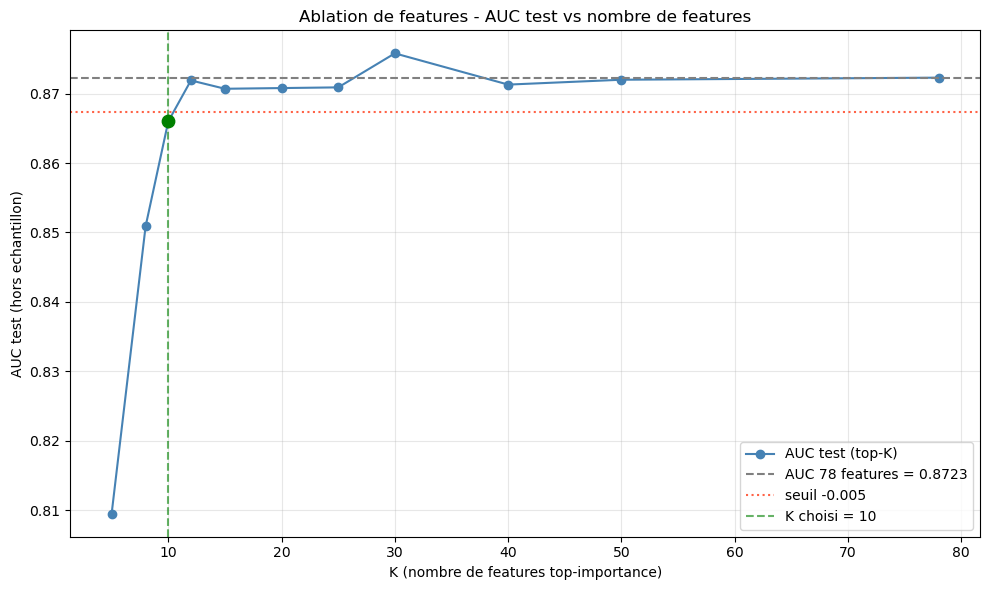

In [18]:
# --- Courbe AUC vs K (montre le plateau) ---
# reference du choix final (10) mise en evidence
K_SELECTED = 10
auc_sel_row = res[res['K'] == K_SELECTED]
auc_sel = float(auc_sel_row['AUC_test'].iloc[0]) if len(auc_sel_row) else None

plt.figure(figsize=(10, 6))
plt.plot(res['K'], res['AUC_test'], 'o-', color='steelblue', label='AUC test (top-K)')
plt.axhline(auc_full, color='gray', ls='--', label=f'AUC 78 features = {auc_full:.4f}')
plt.axhline(auc_full - 0.005, color='tomato', ls=':', label='seuil -0.005')
plt.axvline(K_SELECTED, color='green', ls='--', alpha=0.6, label=f'K choisi = {K_SELECTED}')
if auc_sel is not None:
    plt.scatter([K_SELECTED], [auc_sel], color='green', zorder=5, s=80)
plt.xlabel('K (nombre de features top-importance)')
plt.ylabel('AUC test (hors echantillon)')
plt.title('Ablation de features - AUC test vs nombre de features')
plt.legend(); plt.tight_layout()
plt.show()


## Sélection finale — 10 features figées (100% pur-5m)

L'ablation montre qu'un modèle à ~10-12 features atteint la même AUC que le modèle complet à 78. **On fige 10 features, toutes calculables à partir des seules bougies 5m** (aucune dépendance 1h / 4h / Fear & Greed).

Motivation : garantir la **cohérence entraînement ↔ service temps réel** (le service d'inférence ne reçoit que des bougies 5m) et éliminer tout *train/serving skew*. Le coût en AUC est négligeable (~0.006 vs le modèle à 78 features).

> **Pour ajouter/retirer des features plus tard :** modifier uniquement la liste `FEATURES_SELECTED` ci-dessous, puis relancer 06 → 03 → 05, réaligner `main.py`, redéployer. Toute feature ajoutée doit exister dans le dataset du notebook 01 ; si elle est externe (`_1h`/`_4h`/`fear_greed`), le service devra savoir la calculer en live.


In [19]:
# ============================================================
#  SELECTION FINALE — 10 features figees en dur (100% pur-5m)
#  (issues du classement d'importance ci-dessus, K=10)
# ============================================================
FEATURES_SELECTED = [
    'sell_pressure',
    'upper_wick_ratio',
    'buy_pressure',
    'lower_wick_ratio',
    'atr_pct',
    'ret_288',
    'ema200_slope_48',
    'stoch_k',
    'is_weekend',
    'ema200_slope_12',
]

# --- Garde-fous ---
# 1) toutes les features selectionnees existent dans le dataset
missing = [f for f in FEATURES_SELECTED if f not in FEATURE_COLS]
assert not missing, f'Features absentes du dataset (notebook 01) : {missing}'

# 2) aucune feature externe (garantit la reproductibilite en live 5m)
ext = [f for f in FEATURES_SELECTED if is_external(f)]
assert not ext, f'Features externes interdites dans la selection 5m : {ext}'

# 3) pas de doublon
assert len(FEATURES_SELECTED) == len(set(FEATURES_SELECTED)), 'Doublon dans FEATURES_SELECTED'

print(f'Selection : {len(FEATURES_SELECTED)} features, 100% pur-5m, toutes presentes dans le dataset. OK')


Selection : 10 features, 100% pur-5m, toutes presentes dans le dataset. OK


In [20]:
# --- Verification : AUC du modele reduit (selection finale) vs reference ---
auc_sel_final, sel_model = train_eval(FEATURES_SELECTED)
print(f'AUC test (10 features selectionnees) : {auc_sel_final:.4f}')
print(f'AUC test (78 features reference)     : {auc_full:.4f}')
print(f'Delta                                 : {auc_sel_final - auc_full:+.4f}')
print()
print('Importance relative dans le modele reduit :')
imp_sel = pd.Series(sel_model.feature_importances_, index=FEATURES_SELECTED).sort_values(ascending=False)
for i, (f, val) in enumerate(imp_sel.items(), 1):
    print(f'  {i:2d}. {f:20s} {val:.4f}')


AUC test (10 features selectionnees) : 0.8660
AUC test (78 features reference)     : 0.8723
Delta                                 : -0.0063

Importance relative dans le modele reduit :
   1. buy_pressure         0.2958
   2. sell_pressure        0.2436
   3. upper_wick_ratio     0.2360
   4. lower_wick_ratio     0.1360
   5. atr_pct              0.0489
   6. ret_288              0.0131
   7. stoch_k              0.0096
   8. is_weekend           0.0072
   9. ema200_slope_48      0.0051
  10. ema200_slope_12      0.0048


In [21]:
# ============================================================
#  ECRITURE DE LA SELECTION -> feature_cols_selected.json
#  (NE TOUCHE PAS feature_cols.json / les 78 features)
#  + mise a jour de latest.json pour que 03 et 05 lisent la selection
# ============================================================
from datetime import datetime
DATE = datetime.now().strftime('%Y%m%d')

# 1) fichier de selection versionne + copie sans suffixe
sel_path_dated = PROCESSED + f'feature_cols_selected_{DATE}.json'
sel_path       = PROCESSED + 'feature_cols_selected.json'
for p in (sel_path_dated, sel_path):
    with open(p, 'w') as f:
        json.dump(FEATURES_SELECTED, f, indent=2)
print(f'Ecrit : {sel_path}')
print(f'Ecrit : {sel_path_dated}')

# 2) latest.json : on fait pointer feature_cols vers la SELECTION
#    (sauvegarde de l'ancien pointeur dans feature_cols_full pour tracabilite)
latest_path = PROCESSED + 'latest.json'
if os.path.exists(latest_path):
    with open(latest_path) as f:
        latest_cfg = json.load(f)
else:
    latest_cfg = {}

latest_cfg['feature_cols_full']     = latest_cfg.get('feature_cols', 'feature_cols.json')  # garde la trace des 78
latest_cfg['feature_cols_selected'] = 'feature_cols_selected.json'
latest_cfg['feature_cols']          = 'feature_cols_selected.json'  # <-- 03 et 05 liront la selection
latest_cfg['n_features_selected']   = len(FEATURES_SELECTED)
latest_cfg['ablation_date']         = DATE

with open(latest_path, 'w') as f:
    json.dump(latest_cfg, f, indent=2)

print()
print('latest.json mis a jour :')
print(f"  feature_cols          -> {latest_cfg['feature_cols']}  (la selection, lue par 03/05)")
print(f"  feature_cols_full     -> {latest_cfg['feature_cols_full']}  (les 78, conserve pour re-ablation)")
print()
print('>>> Prochaines etapes : relancer 03 (XGB+RF) puis 05 (LSTM) pour reentrainer sur 10 features,')
print('    puis realigner main.py (10 features pur-5m) et redeployer.')


Ecrit : C:\Users\casir\Desktop\CRYPTOS\data\processed\feature_cols_selected.json
Ecrit : C:\Users\casir\Desktop\CRYPTOS\data\processed\feature_cols_selected_20260808.json

latest.json mis a jour :
  feature_cols          -> feature_cols_selected.json  (la selection, lue par 03/05)
  feature_cols_full     -> feature_cols_20260808.json  (les 78, conserve pour re-ablation)

>>> Prochaines etapes : relancer 03 (XGB+RF) puis 05 (LSTM) pour reentrainer sur 10 features,
    puis realigner main.py (10 features pur-5m) et redeployer.


## Note sur le marqueur « externe / multi-timeframe »

Le marqueur suit la règle par sous-chaîne : une feature est **externe** si son nom contient `_1h`, `_4h` ou `fear_greed`. Deux cas limites (le notebook 01 est la source de vérité) :

- **`vol_realized_1h`** contient `_1h` → marquée *externe*, mais elle est **calculée à partir du 5m** (écart-type de `ret_1` sur 12 périodes). Faux positif de la règle.
- **`trend_aligned_bull`** ne contient aucune sous-chaîne → marquée *pur-5m*, alors qu'elle **dérive** de `trend_bull_1h`/`trend_bull_4h`. Faux négatif de la règle.

Aucune des deux n'est dans la sélection finale (10 features), donc sans impact. Pour une classification stricte « calculable à partir des seules bougies 5m », voir `compute_tf_features` dans le notebook 01.
